# 03 · DBSCAN: vecinos, densidad y ruido
    **Objetivo.** Elegir eps con una curva k-distance y comprobar qué ocurre al mover
    eps y minPts. DBSCAN no recibe K: conecta regiones densas y deja ruido (-1).

**Nota de ejecución.** Celdas ejecutadas en orden con IPython dentro de `.venv`, porque nbconvert no pudo abrir los sockets del kernel en este sandbox. El usuario había verificado la versión previa con nbconvert fuera de esta restricción. Logs de esta revisión en `outputs/logs/`; auxiliares en `outputs/cache/`.

In [1]:
import os, sys, json, time, importlib.util
from pathlib import Path
sys.path.insert(0, "../../src")
sys.dont_write_bytecode = True
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from pcseg.io import read_ply, write_ply, labels_to_rgb
from pcseg.features import voxel_downsample, voxel_ids, build_features
from pcseg.propagate import propagate_labels
from pcseg.metrics import cluster_summary, silhouette_sample, davies_bouldin, stability_ari
# Mostramos los PNG generados sin abrir ventanas gráficas.
plt.switch_backend("module://matplotlib_inline.backend_inline")
# Evitamos que muchos threads hagan más lento un problema pequeño.
thread_limit = threadpool_limits(limits=2)
OUT = Path('../../outputs'); FIG = OUT / 'figs'; ENT = Path('../../entregable'); ENT.mkdir(exist_ok=True)
CACHE = OUT / 'cache'; LOGS = OUT / 'logs'
for folder in (OUT, FIG, CACHE, LOGS): folder.mkdir(exist_ok=True)
(LOGS / 'clase_labels').mkdir(exist_ok=True)
START = time.perf_counter()
SEED = 0
print('Python:', sys.executable, sys.version.split()[0])
assert Path(sys.prefix).resolve() == Path('../../.venv').resolve(), 'Ejecutar con .venv'

Python: /home/evssz/UTEC/6to/machine/clasifica-puntos-pe/.venv/bin/python 3.12.15


### Cómo vamos a dibujar
Usamos una función local de matplotlib: puntos de tamaño 2–2.2 y alpha=0.6. La paleta prioriza colores contrastantes y es la misma en figuras y PLY. Esto cambia la presentación, no el clustering.

In [2]:
# Reordenamos tab20: primero los tonos fuertes; misma paleta en PNG y PLY.
SEGMENT_PALETTE = (np.array(plt.get_cmap('tab20').colors)[
    np.r_[np.arange(0,20,2), np.arange(1,20,2)]] * 255).astype(np.uint8)
def segment_rgb(labels):
    return labels_to_rgb(labels, palette=SEGMENT_PALETTE)

def scatter_views(points, values, path, title, max_points=40000, seed=0):
    # Variante local: puntos visibles y alpha=0.6, sin modificar pcseg.viz.
    if len(points) > max_points:
        idx = np.random.default_rng(seed).choice(len(points), max_points, replace=False)
        points, values = points[idx], values[idx]
    colors = (segment_rgb(values) if values.ndim == 1 else values) / 255.
    fig = plt.figure(figsize=(18,6))
    for j, (axis, label) in enumerate(((1,'y'),(2,'z')), start=1):
        ax = fig.add_subplot(1,3,j)
        ax.scatter(points[:,0],points[:,axis],c=colors,s=2.2,alpha=.6,linewidths=0)
        ax.set(xlabel='x',ylabel=label,title='Superior' if j==1 else 'Lateral',aspect='equal')
    ax = fig.add_subplot(1,3,3,projection='3d')
    ax.scatter(*points.T,c=colors,s=2,alpha=.6,linewidths=0)
    ax.set(xlabel='x',ylabel='y',zlabel='z',title='3D')
    ax.set_box_aspect(np.maximum(np.ptp(points,axis=0),1e-9))
    fig.suptitle(title); fig.tight_layout(); fig.savefig(path,dpi=150); plt.close(fig)

### Recuperamos la misma muestra
No volvemos a sortear puntos: cargamos los índices guardados en 01.

In [3]:
cloud = read_ply('../../data/FARO_Scan_Full_Sub1_down3_with_normals.ply')
sample_idx = np.load(OUT / 'sample_idx.npy')
assert len(np.unique(sample_idx)) == len(sample_idx)
xyz, rgb, normals = (cloud[key][sample_idx] for key in ('xyz', 'rgb', 'normals'))
print('Muestra común:', len(xyz), 'de', len(cloud['xyz']))

Muestra común: 93903 de 1647021


### Antes de comparar: fijemos la regla
Trabajamos siempre con los índices voxel de 01. `rgb` pasa a CIE Lab dentro de
`build_features`: aquí el nombre del conjunto indica el dato de origen.
`height = z - percentil_1(z)` repite la información de z y le da más peso a la altura.

Calculamos silhouette en 1200 puntos (semilla 0) y Davies-Bouldin sin ruido.
Silhouette mayor y DB menor son deseables, pero dependen de la distancia elegida.
Por eso guardamos además `silhouette_comun` y `DB_comun`, siempre sobre las mismas
features completas estandarizadas. No hay ground truth: ninguna métrica demuestra
que los grupos sean objetos físicos. ARI compara corridas, no exactitud.
Los segundos del CSV incluyen ajuste, predicción y estabilidad, y excluyen evaluación y figuras.

In [4]:
FEATURES = {
    'xyz': {},
    'xyz+rgb': {'use_rgb': True},
    'xyz+normales': {'use_normals': True},
    'xyz+rgb+normales+height': {'use_rgb': True, 'use_normals': True, 'use_height': True},
}
def features(name, scaled=True):
    return build_features(xyz, rgb, normals, standardize=scaled, **FEATURES[name])
# Evaluación común: igual distancia y mismas filas para comparar métodos/features.
EVAL = features('xyz+rgb+normales+height')

In [5]:
NB = '03'

rows = []
def record(method, feature, scaled, params, X, labels, seconds, ari, ari_std=0., **extra):
    summary = cluster_summary(labels)
    own_sil = silhouette_sample(X, labels, n=1200, seed=0)
    own_db = davies_bouldin(X, labels)
    common_sil = silhouette_sample(EVAL, labels, n=1200, seed=0)
    common_db = davies_bouldin(EVAL, labels)
    counts = np.array(list(summary['sizes'].values()), dtype=int)
    row_id = f'{NB}_{len(rows):03d}'
    row = dict(id=row_id, metodo=method, features=feature, estandarizado=bool(scaled),
        parametros=json.dumps(params, sort_keys=True), n_fit=extra.get("n_ajuste", len(X)), n_evaluacion=len(X),
        n_clusters=summary['n_clusters'], ruido=summary['noise_frac'],
        silhouette=own_sil, DB=own_db, ARI=ari, ARI_std=ari_std,
        silhouette_comun=common_sil, DB_comun=common_db, segundos=seconds,
        min_cluster_frac=float(counts.min()/len(labels)) if len(counts) else 0.,
        max_cluster_frac=float(counts.max()/len(labels)) if len(counts) else 0., **extra)
    rows.append(row)
    np.save(LOGS / 'clase_labels' / f'{row_id}.npy', labels.astype(np.int32))
    return row

def table():
    df = pd.DataFrame(rows)
    df.to_csv(OUT / f'metricas_{NB}.csv', index=False)
    return df

def view(labels, suffix, title):
    path = FIG / f'{NB}_{suffix}.png'
    scatter_views(xyz, labels, path, title, max_points=30000, seed=0)
    display(Image(filename=str(path)))

def finish(payload):
    payload['segundos_notebook'] = time.perf_counter() - START
    (CACHE / f'clase_resumen_{NB}.json').write_text(json.dumps(payload, indent=2))
    print(payload)

### ¿A qué distancia está el vecino número 10?
Usamos xyz estandarizado para estudiar continuidad espacial. La consulta incluye el propio punto, igual que `min_samples` en DBSCAN. Ordenamos la distancia número 10 y marcamos cuantiles; son candidatos razonables para explorar, no un eps demostrado.

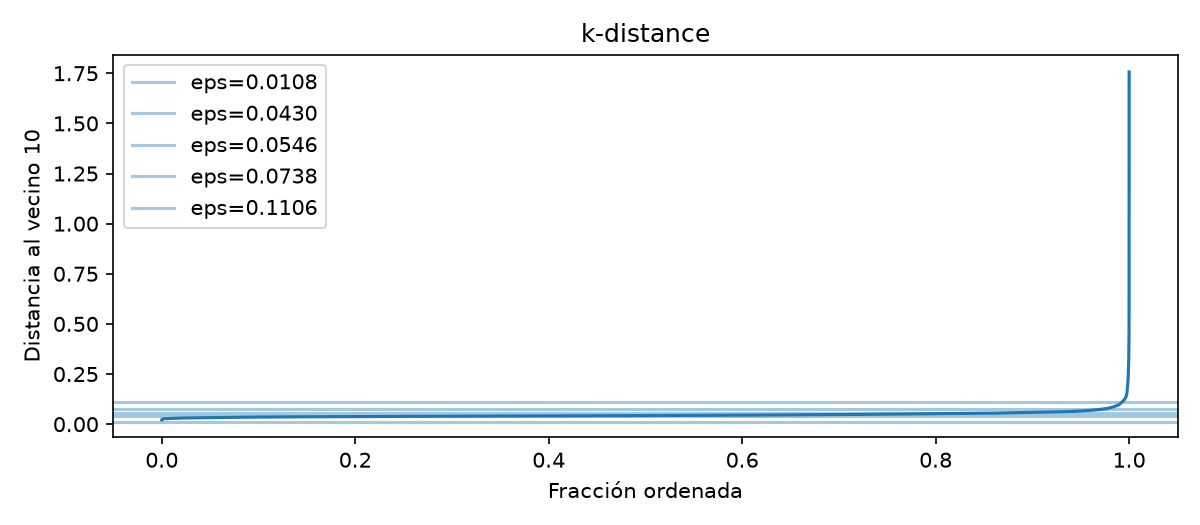

eps candidatos: [0.01075788 0.04303153 0.05459384 0.07376113 0.1106417 ]


In [6]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
X = features('xyz')
neighbors = NearestNeighbors(n_neighbors=10, n_jobs=2).fit(X)
distances, _ = neighbors.kneighbors(X)
kdist = np.sort(distances[:,-1])
q = np.quantile(kdist, [.50,.85,.97])
eps_values = np.unique(np.r_[q[0]*.25, q, q[-1]*1.5])
fig, ax = plt.subplots(figsize=(8,3.5))
ax.plot(np.linspace(0,1,len(kdist)), kdist)
for e in eps_values: ax.axhline(e, alpha=.4, label=f'eps={e:.4f}')
ax.set(xlabel='Fracción ordenada', ylabel='Distancia al vecino 10', title='k-distance'); ax.legend()
fig.tight_layout(); fig.savefig(FIG / '03_kdistance.png', dpi=150); display(Image(filename=str(FIG / '03_kdistance.png'))); plt.close(fig)
print('eps candidatos:', eps_values)

### Una grilla pequeña, con un control de memoria
Probamos dos minPts por eps. Antes contamos vecinos en 1500 puntos para evitar un vecindario demasiado denso. Si supera 1200 vecinos medios reducimos eps y lo anotamos en el CSV. DBSCAN es determinista con este orden fijo: su ARI entre semillas es 1 por construcción; eso no prueba estabilidad ante cambiar eps ni ante remuestrear.

In [7]:
probe = np.random.default_rng(0).choice(len(X), min(1500,len(X)), replace=False)
for proposed in eps_values:
    eps = float(proposed)
    while True:
        neigh = neighbors.radius_neighbors(X[probe], radius=eps, return_distance=False)
        mean_neighbors = float(np.mean([len(v) for v in neigh]))
        if mean_neighbors <= 1200: break
        eps *= .8
    for m in (5, 15):
        tick = time.perf_counter()
        labels = DBSCAN(eps=eps, min_samples=m, n_jobs=2).fit_predict(X)
        elapsed = time.perf_counter()-tick
        ari, sd = stability_ari(lambda data, seed: labels, X, [0,1,2])
        record('dbscan', 'xyz', True, {'eps':eps, 'min_samples':m}, X, labels, elapsed,
               ari, sd, eps_propuesto=float(proposed), vecinos_medios=mean_neighbors)
df = table(); display(df[['parametros','n_clusters','ruido','silhouette','DB','silhouette_comun']])

,parametros,n_clusters,ruido,silhouette,DB,silhouette_comun
0,"{""eps"": 0.010757883561549362, ""min_samples"": 5}",15,0.999159,0.970894,0.035866,0.491068
1,"{""eps"": 0.010757883561549362, ""min_samples"": 15}",0,1.000000,NaN,NaN,NaN
2,"{""eps"": 0.04303153424619745, ""min_samples"": 5}",296,0.023173,-0.674799,1.159677,-0.437387
3,"{""eps"": 0.04303153424619745, ""min_samples"": 15}",548,0.764001,0.100605,0.760492,-0.272120
4,"{""eps"": 0.054593841446837654, ""min_samples"": 5}",115,0.008977,-0.654164,1.083220,-0.409341
5,"{""eps"": 0.054593841446837654, ""min_samples"": 15}",285,0.176150,-0.467535,1.109173,-0.349601
6,"{""eps"": 0.07376113091553832, ""min_samples"": 5}",40,0.004590,-0.564562,1.113844,-0.353350
7,"{""eps"": 0.07376113091553832, ""min_samples"": 15}",51,0.026123,-0.526108,0.959084,-0.389431
8,"{""eps"": 0.11064169637330748, ""min_samples"": 5}",18,0.002034,-0.012221,0.930980,-0.083874
9,"{""eps"": 0.11064169637330748, ""min_samples"": 15}",13,0.005335,-0.381164,0.929519,-0.206514


### Una elección útil y un extremo
Elegimos el mayor silhouette común entre particiones con 2–30 grupos y ruido ≤40%; si ninguna cumple, mostramos la mejor válida y dejamos constancia. Contrastamos con el eps más pequeño. Las métricas excluyen ruido: siempre hay que leerlas junto con su porcentaje.

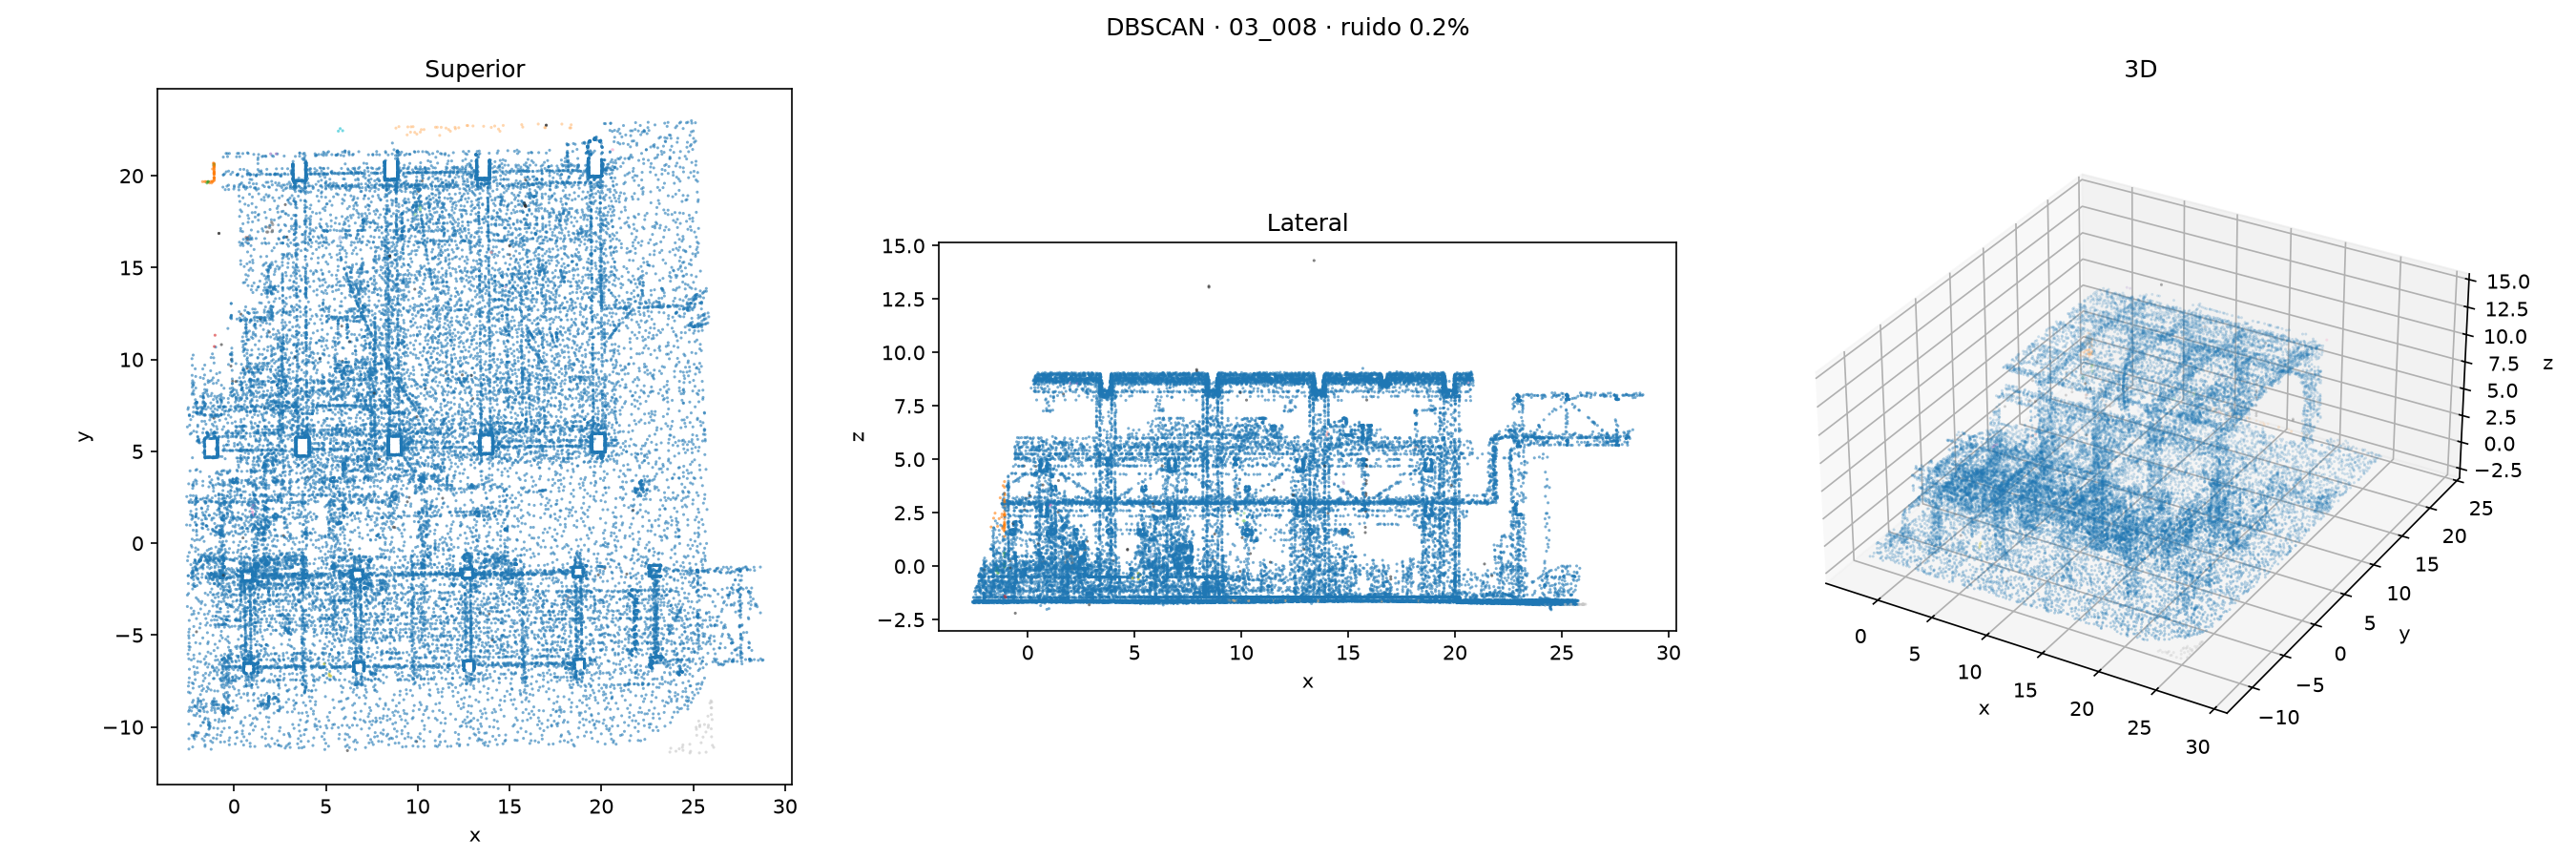

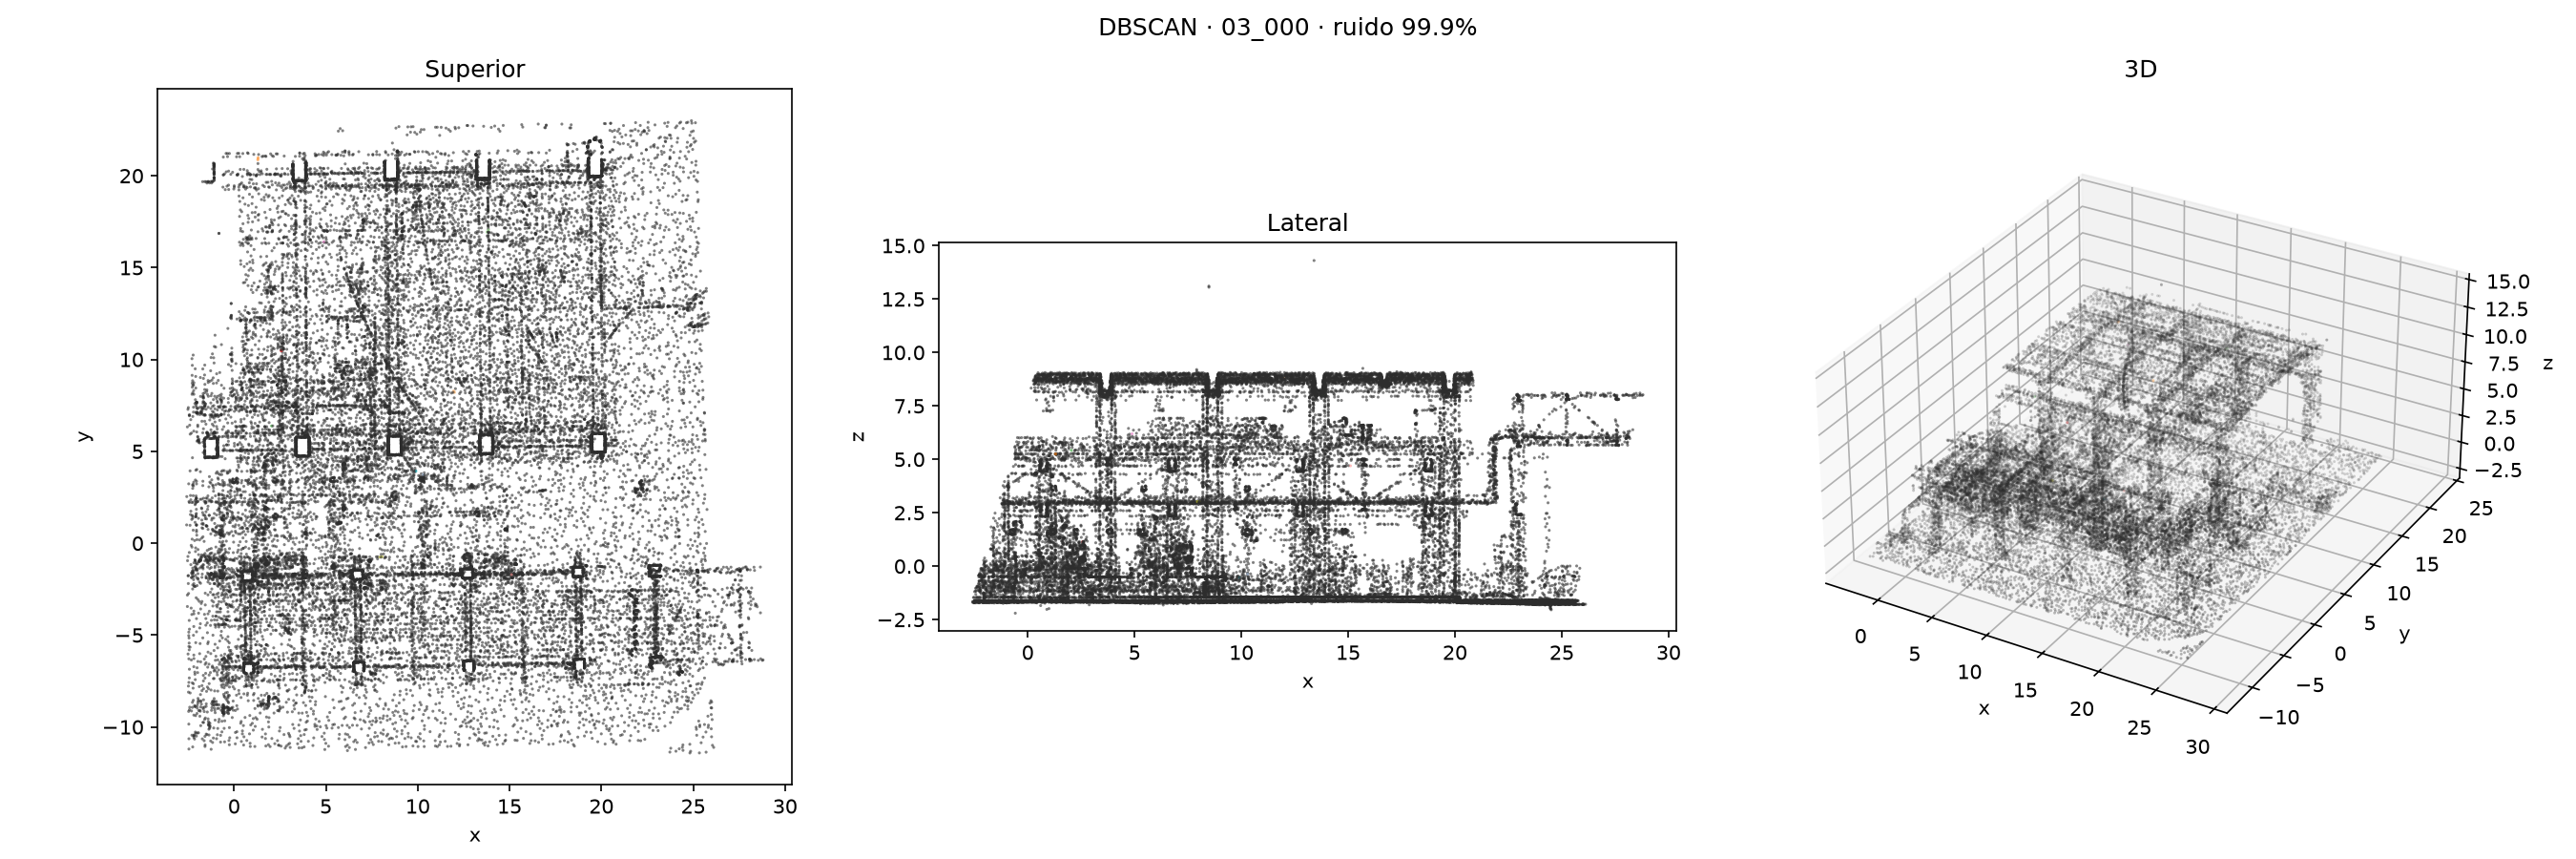

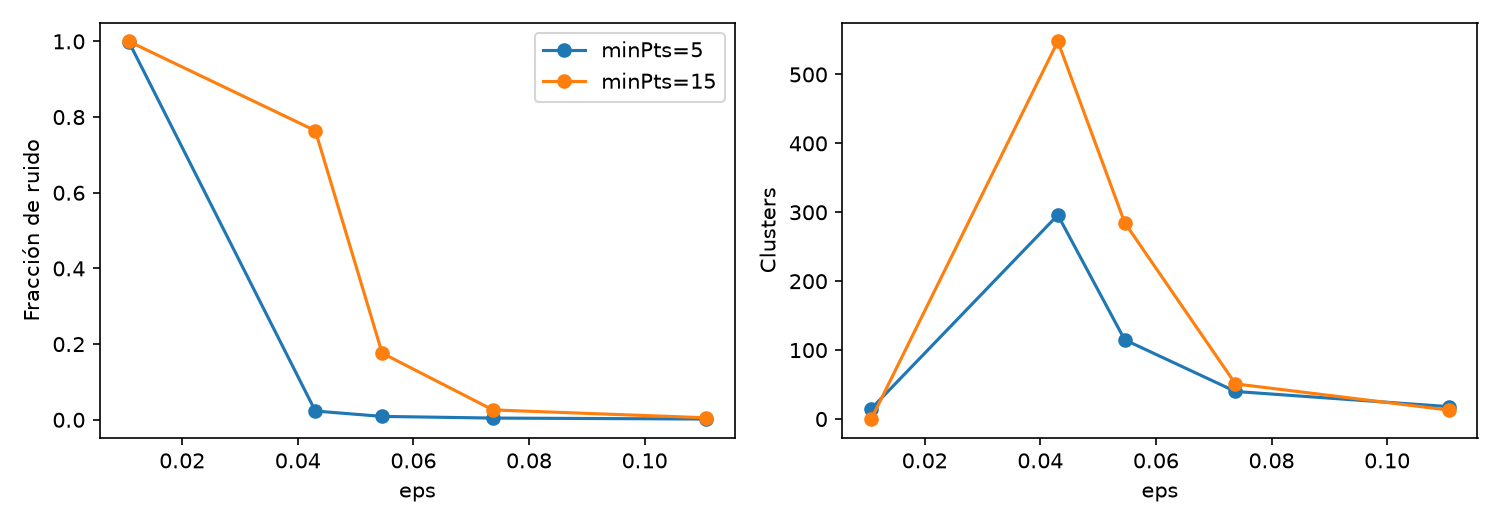

{'mejor': {'id': '03_008', 'metodo': 'dbscan', 'features': 'xyz', 'estandarizado': True, 'parametros': '{"eps": 0.11064169637330748, "min_samples": 5}', 'n_fit': 93903, 'n_evaluacion': 93903, 'n_clusters': 18, 'ruido': 0.0020340138227745654, 'silhouette': -0.012221363484916255, 'DB': 0.9309796010331275, 'ARI': 1.0, 'ARI_std': 0.0, 'silhouette_comun': -0.08387387962653688, 'DB_comun': 1.329437189362563, 'segundos': 0.3756151010020403, 'min_cluster_frac': 5.324643515116663e-05, 'max_cluster_frac': 0.9922260204679296, 'eps_propuesto': 0.11064169637330748, 'vecinos_medios': 69.12}, 'extremo': {'id': '03_000', 'metodo': 'dbscan', 'features': 'xyz', 'estandarizado': True, 'parametros': '{"eps": 0.010757883561549362, "min_samples": 5}', 'n_fit': 93903, 'n_evaluacion': 93903, 'n_clusters': 15, 'ruido': 0.9991587063246116, 'silhouette': 0.9708943618677842, 'DB': 0.035865541900193955, 'ARI': 1.0, 'ARI_std': 0.0, 'silhouette_comun': 0.49106769393566385, 'DB_comun': 0.8818891486759664, 'segundos':

In [8]:
valid = df[df.silhouette_comun.notna() & df.n_clusters.between(2,30) & (df.ruido <= .4)]
fallback = valid.empty
if fallback: valid = df[df.silhouette_comun.notna()]
assert not valid.empty, 'La grilla necesita ampliarse'
best = valid.sort_values('silhouette_comun', ascending=False).iloc[0]
worst = df.iloc[0]
for suffix, row in [('mejor',best),('eps_chico',worst)]:
    view(np.load(LOGS / 'clase_labels' / f'{row.id}.npy'), suffix,
         f'DBSCAN · {row.id} · ruido {row.ruido:.1%}')
fig, ax = plt.subplots(1,2,figsize=(10,3.5))
for m in (5,15):
    p = df[[json.loads(s)['min_samples']==m for s in df.parametros]]
    es = [json.loads(s)['eps'] for s in p.parametros]
    ax[0].plot(es,p.ruido,'o-',label=f'minPts={m}')
    ax[1].plot(es,p.n_clusters,'o-',label=f'minPts={m}')
ax[0].set(xlabel='eps',ylabel='Fracción de ruido'); ax[1].set(xlabel='eps',ylabel='Clusters')
ax[0].legend(); fig.tight_layout(); fig.savefig(FIG/'03_grilla.png',dpi=150); display(Image(filename=str(FIG / '03_grilla.png'))); plt.close(fig)
finish({'mejor':best.to_dict(), 'extremo':worst.to_dict(), 'fallback':fallback,
        'configuraciones':len(df)})

## Qué aprendimos / qué falló

En las 10 pruebas, la elección de la grilla fue 03_008: 18 clusters, ruido 0.2%, silhouette común -0.084, DB común 1.329 y ARI 1.0000. El extremo de eps pequeño dejó 99.9% de ruido y 15 clusters. No fue necesario relajar el filtro para la figura. El grupo mayor reúne 99.2% de la muestra: la figura está dominada por un solo color. Los puntos de ruido no entran en silhouette/DB; ignorar su fracción daría una comparación engañosa. ARI=1 es consecuencia del ajuste determinista y no demuestra robustez a eps.